# Image Compression: Decomposicao de Valores Singulares

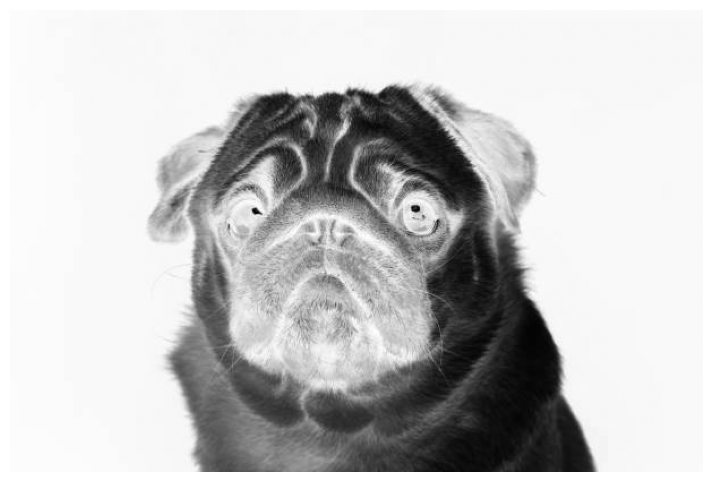

In [1]:
from matplotlib.image import imread
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams['figure.figsize'] = [12,6]

A = imread('../images/dog.jpg')
X = np.mean(A,-1) # convert RGB to grayscale

img = plt.imshow(256-X)
img.set_cmap('gray')
plt.axis('off')
plt.show()

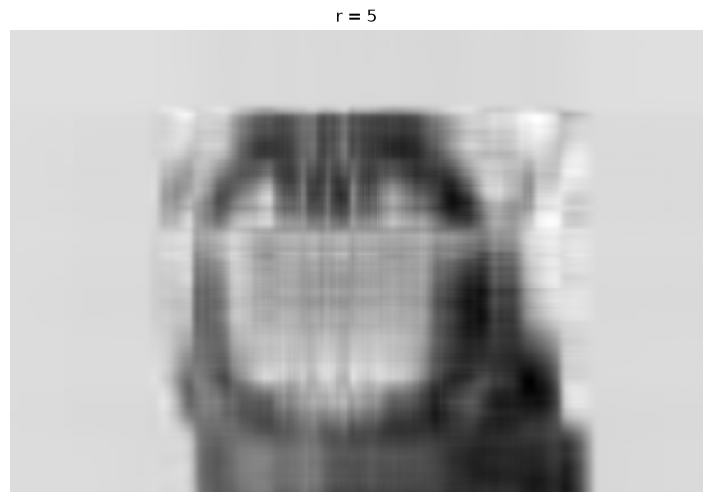

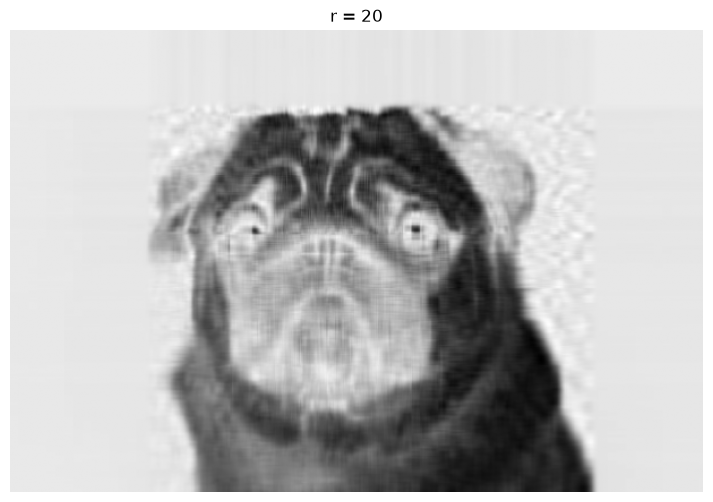

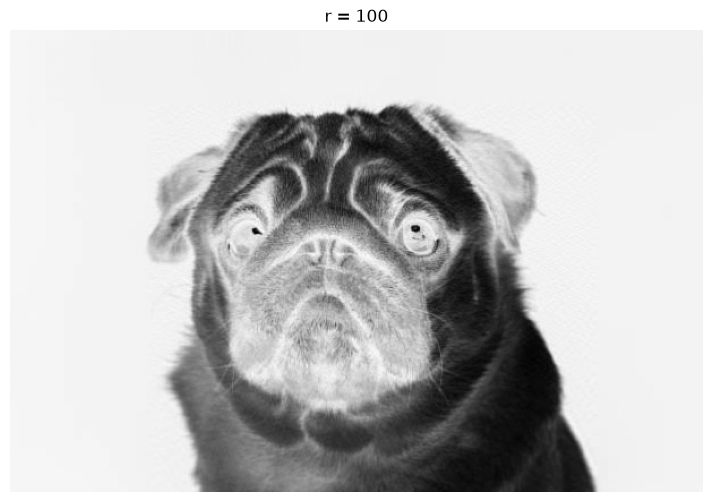

In [2]:
U, S, VT = np.linalg.svd(X, full_matrices=False)
S = np.diag(S)

j = 0
for r in (5, 20, 100):
    # consctruct aproximate image
    Xapprox = U[:, :r] @ S[0:r, :r] @ VT[:r, :]
    plt.figure(j+1)
    j+=1
    img = plt.imshow(256-Xapprox)
    img.set_cmap('gray')
    plt.axis('off')
    plt.title('r = ' + str(r))
    plt.show()

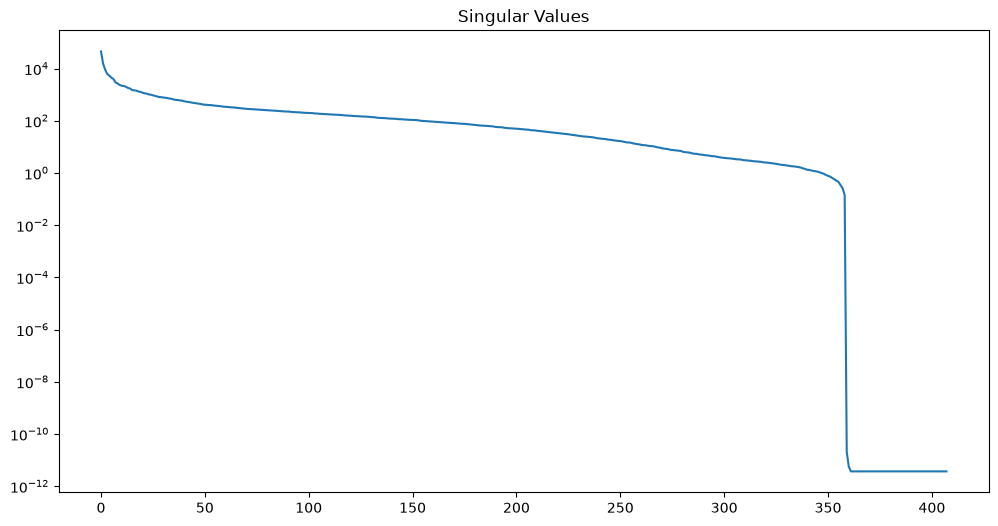

In [3]:
plt.figure(1)
plt.semilogy(np.diag(S))
plt.title('Singular Values')
plt.show()

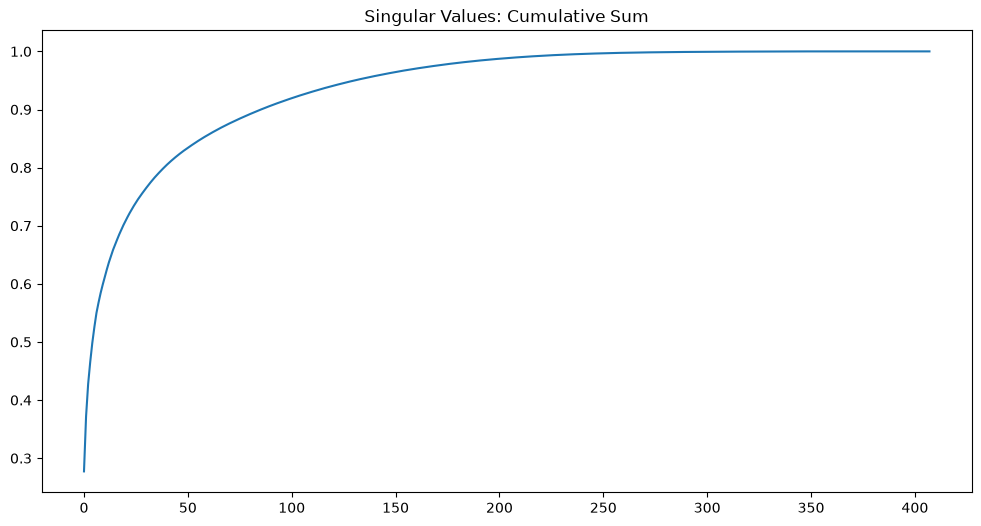

In [4]:
plt.figure(2)
plt.plot(np.cumsum(np.diag(S))/np.sum(np.diag(S)))
plt.title('Singular Values: Cumulative Sum')
plt.show()